# Exploratory Data Analysis — AI-Based Resume Screening and Candidate Shortlisting System
**HCLTech Career Shaper Programme | Project 34 | Ashish Kumar Pal (2300321530045)**

This notebook analyses `dataset.csv` (500 synthetic resume feature vectors provided by the programme). It covers loading, quality checks, cleaning and pre-processing, six visualisations, and a small scikit-learn sanity check.

**How this relates to the main project:** the screening application reads resume PDFs and scores them with Gemini and Sentence Transformers; it is not trained on this file. This dataset is used here for exploratory analysis only.

## 1. Setup and loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PURPLE, LILAC = "#3D1A6E", "#D9C3F0"

df = pd.read_csv("dataset.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (500, 8)


,resume_id,job_role,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted
0,R0001,Data_Analyst,3,8,73,0.129,46.1,0
1,R0002,Data_Analyst,5,6,67,0.747,97.7,1
2,R0003,Software_Engineer,9,11,89,0.713,61.1,1
3,R0004,HR_Executive,4,8,99,0.459,79.9,0
4,R0005,Software_Engineer,10,4,91,0.608,57.8,1


## 2. Overview: data types and summary statistics

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resume_id        500 non-null    str    
 1   job_role         500 non-null    str    
 2   years_exp        500 non-null    int64  
 3   skills_matched   500 non-null    int64  
 4   education_score  500 non-null    int64  
 5   keyword_density  500 non-null    float64
 6   predicted_score  500 non-null    float64
 7   shortlisted      500 non-null    int64  
dtypes: float64(2), int64(4), str(2)
memory usage: 31.4 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
years_exp,500.0,7.46,4.70,0.0,3.0,7.00,12.0,15.0
skills_matched,500.0,8.85,3.73,3.0,6.0,9.00,12.0,15.0
education_score,500.0,80.31,11.98,60.0,69.0,80.00,91.0,100.0
keyword_density,500.0,0.49,0.23,0.1,0.3,0.49,0.7,0.9
predicted_score,500.0,68.03,17.57,40.1,51.3,67.70,83.3,100.0
shortlisted,500.0,0.35,0.48,0.0,0.0,0.00,1.0,1.0


## 3. Data quality checks

In [4]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate resume_id values:", df["resume_id"].duplicated().sum())

# Range checks (valid ranges taken from the observed, plausible values of each column)
ranges = {"years_exp": (0, 50), "skills_matched": (0, 50), "education_score": (0, 100),
          "keyword_density": (0, 1), "predicted_score": (0, 100)}
print("\nValues outside the valid range:")
for col, (lo, hi) in ranges.items():
    print(f"  {col}: {(~df[col].between(lo, hi)).sum()}")
print("\nUnique shortlisted values:", sorted(df["shortlisted"].unique().tolist()))
print("Job roles:", sorted(df["job_role"].unique()))

# Outlier check using the 1.5 x IQR rule
print("\nOutliers (1.5 x IQR rule):")
for col in ranges:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"  {col}: {n}")

Missing values per column:
resume_id          0
job_role           0
years_exp          0
skills_matched     0
education_score    0
keyword_density    0
predicted_score    0
shortlisted        0

Duplicate rows: 0
Duplicate resume_id values: 0

Values outside the valid range:
  years_exp: 0
  skills_matched: 0
  education_score: 0
  keyword_density: 0
  predicted_score: 0

Unique shortlisted values: [0, 1]
Job roles: ['Data_Analyst', 'HR_Executive', 'Project_Manager', 'QA_Engineer', 'Software_Engineer']

Outliers (1.5 x IQR rule):
  years_exp: 0
  skills_matched: 0
  education_score: 0
  keyword_density: 0
  predicted_score: 0


**Result:** no missing values, no duplicate rows or IDs, no out-of-range values and no IQR outliers, so no rows needed to be removed.

## 4. Cleaning and pre-processing

In [5]:
clean = df.copy()
clean["job_role"] = clean["job_role"].str.strip()           # remove stray whitespace
clean = clean.drop_duplicates().dropna()                     # no-ops here, kept for reproducibility
clean["years_exp"] = clean["years_exp"].astype(int)
clean["skills_matched"] = clean["skills_matched"].astype(int)
clean["education_score"] = clean["education_score"].astype(int)
clean["shortlisted_label"] = clean["shortlisted"].map({1: "Y", 0: "N"})   # brief lists shortlisted as Y/N

clean.to_csv("dataset_cleaned.csv", index=False)
print("Cleaned shape:", clean.shape, "| rows removed:", len(df) - len(clean))
clean.head()

Cleaned shape: (500, 9) | rows removed: 0


,resume_id,job_role,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted,shortlisted_label
0,R0001,Data_Analyst,3,8,73,0.129,46.1,0,N
1,R0002,Data_Analyst,5,6,67,0.747,97.7,1,Y
2,R0003,Software_Engineer,9,11,89,0.713,61.1,1,Y
3,R0004,HR_Executive,4,8,99,0.459,79.9,0,N
4,R0005,Software_Engineer,10,4,91,0.608,57.8,1,Y


## 5. Visualisations

### 5.1 Resumes per job role and shortlisting rate by role

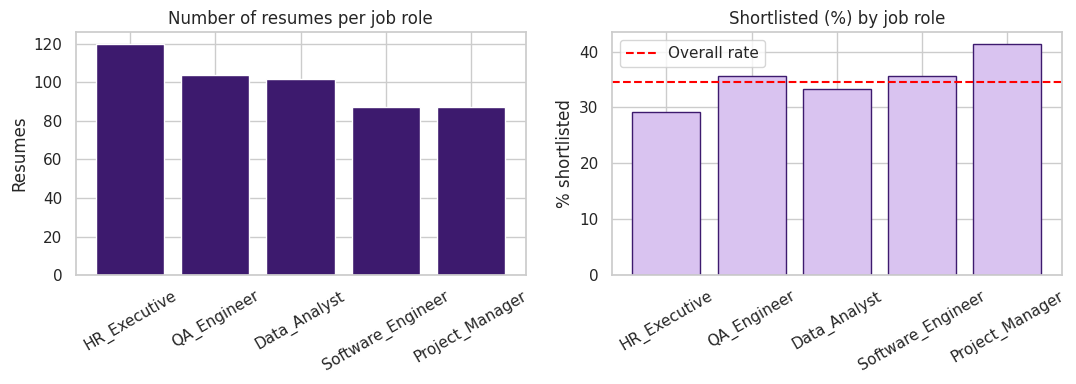

In [6]:
counts = clean["job_role"].value_counts()
rate = clean.groupby("job_role")["shortlisted"].mean().mul(100).reindex(counts.index)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(counts.index, counts.values, color=PURPLE)
ax[0].set_title("Number of resumes per job role"); ax[0].set_ylabel("Resumes")
ax[1].bar(rate.index, rate.values, color=LILAC, edgecolor=PURPLE)
ax[1].axhline(clean["shortlisted"].mean() * 100, color="red", ls="--", label="Overall rate")
ax[1].set_title("Shortlisted (%) by job role"); ax[1].set_ylabel("% shortlisted"); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 5.2 Distribution of each numeric feature

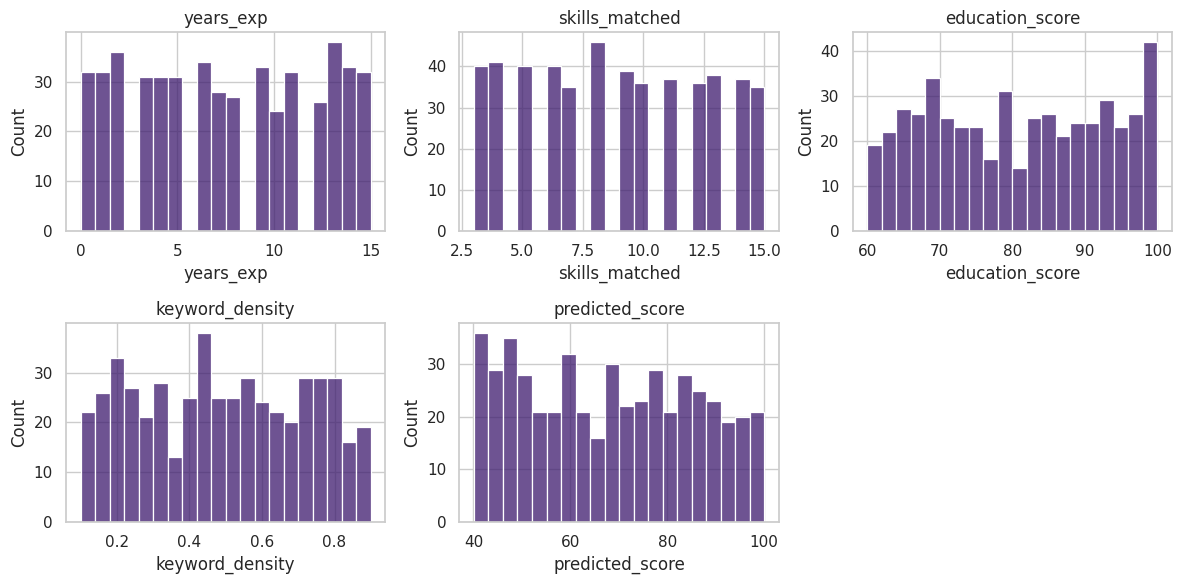

In [7]:
features = ["years_exp", "skills_matched", "education_score", "keyword_density", "predicted_score"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(clean[col], bins=20, color=PURPLE, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 5.3 Do shortlisted and non-shortlisted resumes look different?

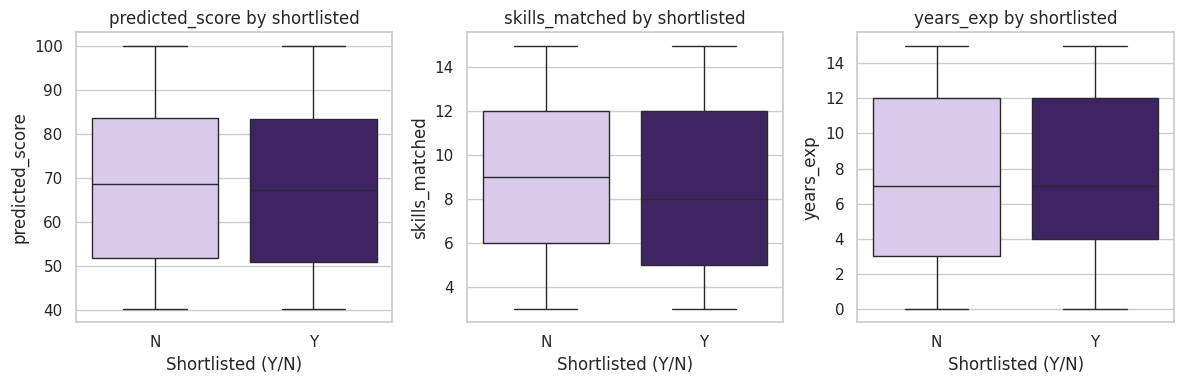

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["predicted_score", "skills_matched", "years_exp"]):
    sns.boxplot(data=clean, x="shortlisted_label", y=col, order=["N", "Y"],
                palette={"N": LILAC, "Y": PURPLE}, hue="shortlisted_label", legend=False, ax=ax)
    ax.set_title(f"{col} by shortlisted"); ax.set_xlabel("Shortlisted (Y/N)")
plt.tight_layout(); plt.show()

### 5.4 Correlation heatmap

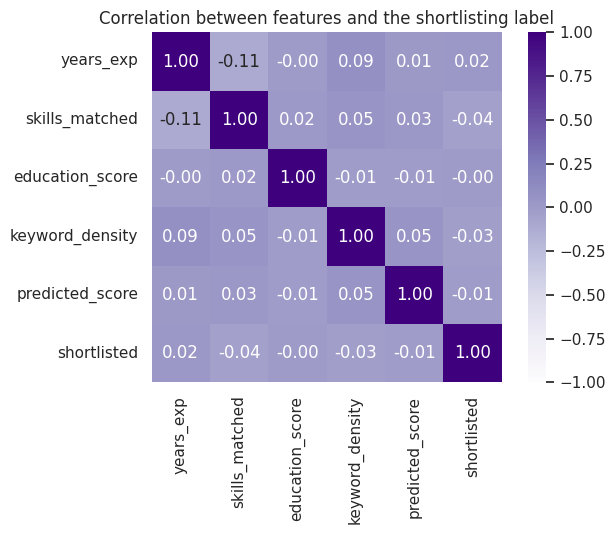

In [9]:
corr = clean[features + ["shortlisted"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Purples", vmin=-1, vmax=1, square=True)
plt.title("Correlation between features and the shortlisting label")
plt.tight_layout(); plt.show()

### 5.5 Skills matched versus predicted score

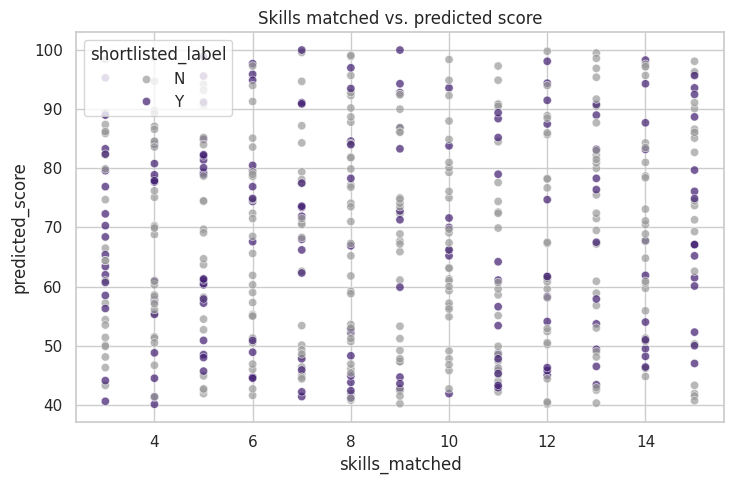

In [10]:
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=clean, x="skills_matched", y="predicted_score", hue="shortlisted_label",
                hue_order=["N", "Y"], palette={"N": "#9a9a9a", "Y": PURPLE}, alpha=0.7)
plt.title("Skills matched vs. predicted score"); plt.tight_layout(); plt.show()

### 5.6 Shortlisting rate by experience band and by predicted-score band

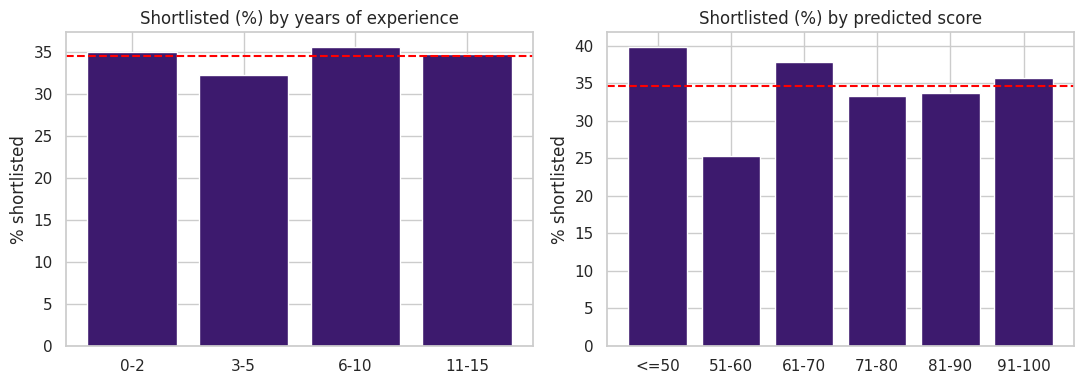

In [11]:
clean["exp_band"] = pd.cut(clean["years_exp"], [-1, 2, 5, 10, 15], labels=["0-2", "3-5", "6-10", "11-15"])
clean["score_band"] = pd.cut(clean["predicted_score"], [0, 50, 60, 70, 80, 90, 100],
                             labels=["<=50", "51-60", "61-70", "71-80", "81-90", "91-100"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col, title in [(ax[0], "exp_band", "Years of experience"), (ax[1], "score_band", "Predicted score")]:
    r = clean.groupby(col, observed=True)["shortlisted"].mean() * 100
    a.bar(r.index.astype(str), r.values, color=PURPLE)
    a.axhline(clean["shortlisted"].mean() * 100, color="red", ls="--")
    a.set_title(f"Shortlisted (%) by {title.lower()}"); a.set_ylabel("% shortlisted")
plt.tight_layout(); plt.show()

## 6. Key numbers

In [12]:
print("Correlation of each feature with 'shortlisted':")
print(corr["shortlisted"].drop("shortlisted").round(3).to_string())
hi = clean[clean["predicted_score"] >= 70]["shortlisted"].mean()
lo = clean[clean["predicted_score"] < 70]["shortlisted"].mean()
print(f"\nShortlisted rate when predicted_score >= 70: {hi:.1%}")
print(f"Shortlisted rate when predicted_score  < 70: {lo:.1%}")
print(f"Overall shortlisted rate: {clean['shortlisted'].mean():.1%}")

Correlation of each feature with 'shortlisted':
years_exp          0.025
skills_matched    -0.044
education_score   -0.004
keyword_density   -0.029
predicted_score   -0.009

Shortlisted rate when predicted_score >= 70: 34.5%
Shortlisted rate when predicted_score  < 70: 34.7%
Overall shortlisted rate: 34.6%


## 7. Sanity check with scikit-learn

If the features carried information about shortlisting, a simple classifier should beat the baseline of always predicting the majority class ("not shortlisted"). Using 5-fold stratified cross-validation:

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = pd.get_dummies(clean[features + ["job_role"]], columns=["job_role"], drop_first=True)
y = clean["shortlisted"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = max(y.mean(), 1 - y.mean())
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
rows = [{"Model": "Majority-class baseline", "Accuracy": baseline, "ROC-AUC": 0.5}]
for name, model in models.items():
    rows.append({"Model": name,
                 "Accuracy": cross_val_score(model, X, y, cv=cv, scoring="accuracy").mean(),
                 "ROC-AUC": cross_val_score(model, X, y, cv=cv, scoring="roc_auc").mean()})
pd.DataFrame(rows).round(3)

,Model,Accuracy,ROC-AUC
0,Majority-class baseline,0.654,0.500
1,Logistic Regression,0.646,0.489
2,Random Forest,0.572,0.431


## 8. Findings

1. **Data quality is good.** 500 rows and 8 columns, with no missing values, duplicates or outliers. Cleaning therefore changed nothing except adding a `shortlisted_label` (Y/N) column; the result is saved as `dataset_cleaned.csv`.
2. **Five job roles, not evenly sized.** HR_Executive has the most resumes (120) and Software_Engineer and Project_Manager the fewest (87 each). About 35% of all resumes are shortlisted, with role-level rates between roughly 29% (HR_Executive) and 41% (Project_Manager).
3. **The features do not explain the shortlisting label.** Every feature's correlation with `shortlisted` is below 0.05 in absolute value. Resumes with `predicted_score` of 70 or more are shortlisted at the same rate (about 35%) as those below 70.
4. **A classifier cannot beat the baseline.** Logistic regression and a random forest score at or below the majority-class baseline (about 65% accuracy) with ROC-AUC near or below 0.5, which means the label behaves like random noise relative to these features.

**Interpretation:** this looks like randomly generated synthetic data, so it is suitable for practising EDA but not for training a meaningful shortlisting model. This is why the screening application is evaluated separately, on synthetic resume PDFs with a known expected ranking, rather than being trained on this file. If more rows are generated, the shortlisting label should be made to depend on the features so that models have a real signal to learn.